In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- Load Data ----------
df = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Merged.xlsx")

# ---------- Rename columns ----------
df = df.rename(columns={
    df.columns[0]: 'time',
    df.columns[1]: 'price_de_lu',
    df.columns[2]: 'price_neighbors',
    df.columns[3]: 'temp',
    df.columns[4]: 'sunshine',
    df.columns[5]: 'wind_speed',
    df.columns[6]: 'wind_dir',
    df.columns[7]: 'is_day',
    df.columns[8]: 'precip',
    df.columns[9]: 'radiation',
})

# ---------- Set datetime index ----------
df['time'] = pd.to_datetime(df['time'], errors='coerce')
df = df.dropna(subset=['time']).set_index('time').sort_index()
df = df[~df.index.duplicated(keep='first')]

print("Columns:", df.columns.tolist())
print("Rows   :", len(df))
print("Range  :", df.index.min(), "→", df.index.max())

# ---------- Add time period ----------
def get_time_period(hour):
    if 0 <= hour < 5:    return '1. Late Night (00-05)'
    elif 5 <= hour < 8:  return '2. Early Morning (05-08)'
    elif 8 <= hour < 11: return '3. Morning (08-11)'
    elif 11 <= hour < 14:return '4. Noon (11-14)'
    elif 14 <= hour < 17:return '5. Afternoon (14-17)'
    elif 17 <= hour < 21:return '6. Evening (17-21)'
    else:                return '7. Night (21-24)'

df['period'] = df.index.hour.map(get_time_period)

period_order = [
    '1. Late Night (00-05)', '2. Early Morning (05-08)', '3. Morning (08-11)',
    '4. Noon (11-14)', '5. Afternoon (14-17)', '6. Evening (17-21)',
    '7. Night (21-24)'
]
df['period'] = pd.Categorical(df['period'], categories=period_order, ordered=True)

print("'period' column added:", 'period' in df.columns)
print(df.head())
print(df.index.min(), df.index.max())
print(df.dtypes)

Columns: ['price_de_lu', 'price_neighbors', 'temp', 'sunshine', 'wind_speed', 'wind_dir', 'is_day', 'precip', 'radiation']
Rows   : 61144
Range  : 2025-01-01 00:00:00 → 2026-09-29 23:45:00
'period' column added: True
                     price_de_lu  price_neighbors    temp  sunshine  \
time                                                                  
2025-01-01 00:00:00         2.16            27.99  0.9455       0.0   
2025-01-01 00:15:00         2.16            27.99  1.0455       0.0   
2025-01-01 00:30:00         2.16            27.99  1.1955       0.0   
2025-01-01 00:45:00         2.16            27.99  1.3455       0.0   
2025-01-01 01:00:00         1.60            29.36  1.4955       0.0   

                     wind_speed    wind_dir  is_day  precip  radiation  \
time                                                                     
2025-01-01 00:00:00    9.660746  216.158279       0     0.0          0   
2025-01-01 00:15:00    9.765244  214.992096       0     0.0    

In [10]:
missing = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing %": df.isna().mean() * 100,
    "Zero count": (df == 0).sum()
})

#print(missing)

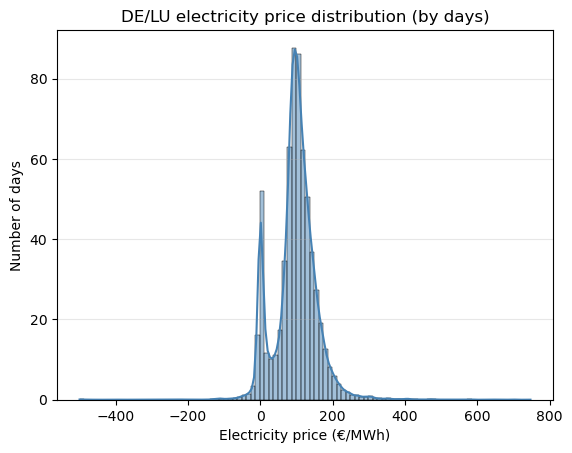

count    61144.000000
mean        97.130509
std         60.076603
min       -499.990000
25%         72.980000
50%         99.400000
75%        127.410000
max        747.100000
Name: price_de_lu, dtype: float64
0.01    -20.0900
0.05     -0.1200
0.25     72.9800
0.50     99.4000
0.75    127.4100
0.95    183.6555
0.99    260.6771
Name: price_de_lu, dtype: float64
Excess Kurtosis: 8.28296347854849
Skewness: 0.41718259754347764


In [22]:
# 1. Distribution of electricity price
# frequency by day : 24h * 4 = 96
weights = np.ones(len(df)) / 96

# create histogram
sns.histplot(
    data=df,
    x="price_de_lu",
    bins=100,
    kde=True,
    weights=weights,
    color="steelblue"
)
plt.xlabel("Electricity price (€/MWh)")
plt.ylabel("Number of days")
plt.title("DE/LU electricity price distribution (by days)")
plt.grid(axis="y", alpha=0.3)
plt.show()

# statistics data
print(df["price_de_lu"].describe())
print(df["price_de_lu"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))
print("Excess Kurtosis:", df["price_de_lu"].kurt())
print("Skewness:", df["price_de_lu"].skew())   

In [28]:
# 2. New: Divide the day into time periods based on German market characteristics
# Ensure the periods are ordered chronologically
period_order = [
    '1. Late Night (00-05)', '2. Early Morning (05-08)', '3. Morning (08-11)',
    '4. Noon (11-14)', '5. Afternoon (14-17)', '6. Evening (17-21)',
    '7. Night (21-24)'
]
df['period'] = pd.Categorical(df['period'], categories=period_order, ordered=True)

# 3. Statistics by Time Period
period_stats = df.groupby('period', observed=False)['price_de_lu'].agg(
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std='std',
    Neg_Price_Pct=lambda x: (x <= 0).mean() * 100
).round(2)

print("\n=== Electricity Price Statistics by Time Period (€/MWh) ===")
print(period_stats)


=== Electricity Price Statistics by Time Period (€/MWh) ===
                            Mean  Median     Min     Max    Std  Neg_Price_Pct
period                                                                        
1. Late Night (00-05)      95.99   94.92   -5.09  219.74  35.00           0.97
2. Early Morning (05-08)  111.96  108.57   -4.99  392.15  44.04           0.98
3. Morning (08-11)         94.97   98.19  -60.00  431.99  55.84           7.00
4. Noon (11-14)            49.44   54.85 -499.99  393.86  59.13          27.71
5. Afternoon (14-17)       61.48   70.19 -499.99  402.12  64.19          23.97
6. Evening (17-21)        133.85  125.75  -16.71  747.10  65.92           1.50
7. Night (21-24)          120.73  113.21   -1.25  693.47  47.28           0.18


In [23]:
# ---------- Frequency of low / negative prices ----------
thresholds = [0, 10, 20, 30, 50]

print("=" * 55)
print(f"{'Threshold':>12} {'Count':>10} {'Share':>10}")
print("=" * 55)
for t in thresholds:
    n = (df['price_de_lu'] <= t).sum()
    pct = n / len(df) * 100
    print(f"  price <= {t:>3}   {n:>10,}   {pct:>9.2f}%")
print("=" * 55)

# ---------- By year ----------
df['year'] = df.index.year
print("\nNegative price share by year:")
print(df.groupby('year')['price_de_lu'].apply(lambda x: (x <= 0).mean() * 100).round(2))

# ---------- By month ----------
df['month'] = df.index.month
print("\nNegative price share by month (%):")
print(df.groupby('month')['price_de_lu'].apply(lambda x: (x <= 0).mean() * 100).round(2))

   Threshold      Count      Share
  price <=   0        4,850        7.93%
  price <=  10        7,160       11.71%
  price <=  20        8,195       13.40%
  price <=  30        9,001       14.72%
  price <=  50       10,667       17.45%

Negative price share by year:
year
2025    7.55
2026    8.44
Name: price_de_lu, dtype: float64

Negative price share by month (%):
month
1      1.53
2      0.61
3      5.27
4     15.21
5     15.66
6     14.79
7      7.73
8      9.76
9      8.44
10     7.86
11     0.00
12     0.00
Name: price_de_lu, dtype: float64


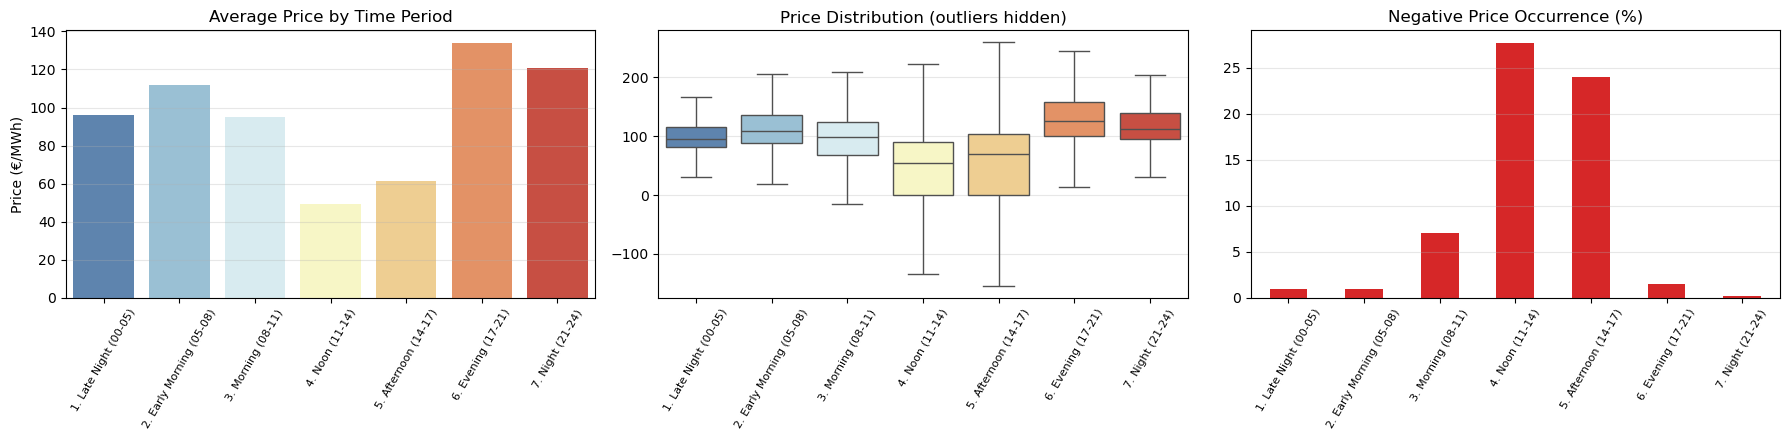

In [27]:
# ==========================================
# 4. Visualizations by Time Period (compact)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 4.1 Average price
sns.barplot(data=df, x='period', y='price_de_lu', errorbar=None,
            hue='period', palette='RdYlBu_r', legend=False, ax=axes[0])
axes[0].set_title('Average Price by Time Period')
axes[0].set_xlabel('')
axes[0].set_ylabel('Price (€/MWh)')
axes[0].tick_params(axis='x', rotation=60, labelsize=8)
axes[0].grid(axis='y', alpha=0.3)

# 4.2 Boxplot
sns.boxplot(data=df, x='period', y='price_de_lu',
            hue='period', palette='RdYlBu_r', legend=False,
            showfliers=False, ax=axes[1])
axes[1].set_title('Price Distribution (outliers hidden)')
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=60, labelsize=8)
axes[1].grid(axis='y', alpha=0.3)

# 4.3 Negative price frequency
neg_ratio = df.groupby('period', observed=False)['price_de_lu'].apply(
    lambda x: (x <= 0).mean() * 100
)
neg_ratio.plot(kind='bar', color='tab:red', ax=axes[2])
axes[2].set_title('Negative Price Occurrence (%)')
axes[2].set_xlabel('')
axes[2].set_ylabel('')
axes[2].tick_params(axis='x', rotation=60, labelsize=8)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Preliminary Analysis: Key Findings

- **Distribution**: Strongly non-normal — bimodal, right-skewed (skew 0.42), fat-tailed (kurtosis 8.28). Range: -500 to +747 €/MWh.
- **Intraday pattern**: Dual-valley/dual-peak — noon and afternoon cheapest (approx. 50–61 €/MWh), evening and night most expensive (approx. 121–134 €/MWh).
- **Low-price frequency**: 7.9% of the time price ≤ 0; 17.5% ≤ 50 €/MWh. Negative prices concentrated in April–June, absent in Nov–Dec.

**Summary:** Frequent low/negative prices provide charging windows; evening peaks provide discharge opportunities — a solid basis for battery arbitrage.